In [ ]:
import ee
import geemap
import numpy as np
import matplotlib.pyplot as plt

ee.Authenticate()
ee.Initialize(project='-') #project id

In [ ]:
# AOI
# Rzeszów (Urban)
point_rzeszow = ee.Geometry.Point([21.9991, 50.0412])
aoi_urban = point_rzeszow.buffer(2500).bounds()  # ~5x5 km box

# Jezioro Solińskie 
point_solina = ee.Geometry.Point([22.4550, 49.3950])
aoi_natural = point_solina.buffer(2500).bounds()

date_start = '2023-06-01'
date_end = '2023-08-31'

def get_sentinel2_bands(aoi):
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(aoi)
          .filterDate(date_start, date_end)
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))
          .sort('CLOUDY_PIXEL_PERCENTAGE')
          .first()
          .clip(aoi))
    
    b2 = geemap.ee_to_numpy(s2.select('B2'), region=aoi)
    b3 = geemap.ee_to_numpy(s2.select('B3'), region=aoi)
    b4 = geemap.ee_to_numpy(s2.select('B4'), region=aoi)
    return {'B02 (Blue)': b2.squeeze(), 'B03 (Green)': b3.squeeze(), 'B04 (Red)': b4.squeeze()}

def get_sentinel1_bands(aoi):
    s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
          .filterBounds(aoi)
          .filterDate(date_start, date_end)
          .filter(ee.Filter.eq('instrumentMode', 'IW'))
          .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
          .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
          .first()
          .clip(aoi))
    
    vv_db = geemap.ee_to_numpy(s1.select('VV'), region=aoi).squeeze()
    vh_db = geemap.ee_to_numpy(s1.select('VH'), region=aoi).squeeze()
    vv_linear = np.power(10.0, vv_db / 10.0)
    vh_linear = np.power(10.0, vh_db / 10.0)
    return {'VV': vv_linear, 'VH': vh_linear}

print("Fetching Sentinel-2 and Sentinel-1 data from GEE...")
s2_urban = get_sentinel2_bands(aoi_urban)
s2_natural = get_sentinel2_bands(aoi_natural)
s1_urban = get_sentinel1_bands(aoi_urban)
s1_natural = get_sentinel1_bands(aoi_natural)

print("Data successfully loaded from Google Earth Engine.")

Fetching Sentinel-2 and Sentinel-1 data from GEE...
Data successfully loaded from Google Earth Engine.


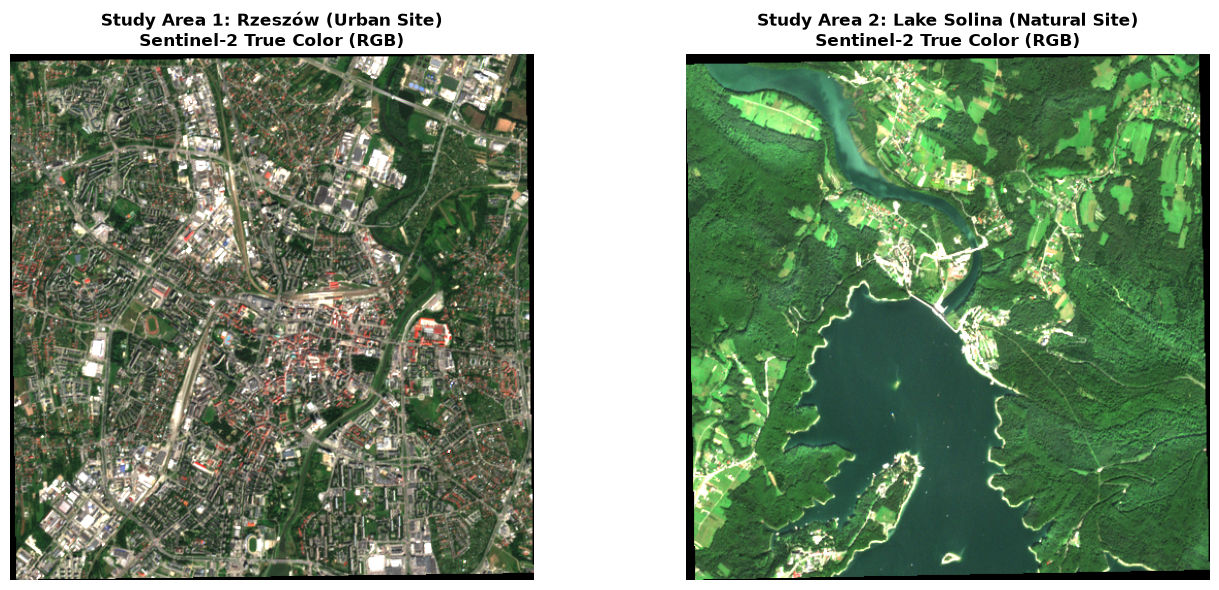

In [ ]:
# Visual presentation
# Rzeszów (Urban) VS Lake Solina (Natural)

def make_rgb(band_dict):
    r = band_dict['B04 (Red)']
    g = band_dict['B03 (Green)']
    b = band_dict['B02 (Blue)']
    
    rgb = np.dstack((r, g, b))
    p2, p98 = np.percentile(rgb, (2, 98))
    rgb_scaled = np.clip((rgb - p2) / (p98 - p2), 0, 1)
    return rgb_scaled

rgb_rzeszow = make_rgb(s2_urban)
rgb_solina = make_rgb(s2_natural)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(rgb_rzeszow)
axes[0].set_title('Study Area 1: Rzeszów (Urban Site)\nSentinel-2 True Color (RGB)', fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(rgb_solina)
axes[1].set_title('Study Area 2: Lake Solina (Natural Site)\nSentinel-2 True Color (RGB)', fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

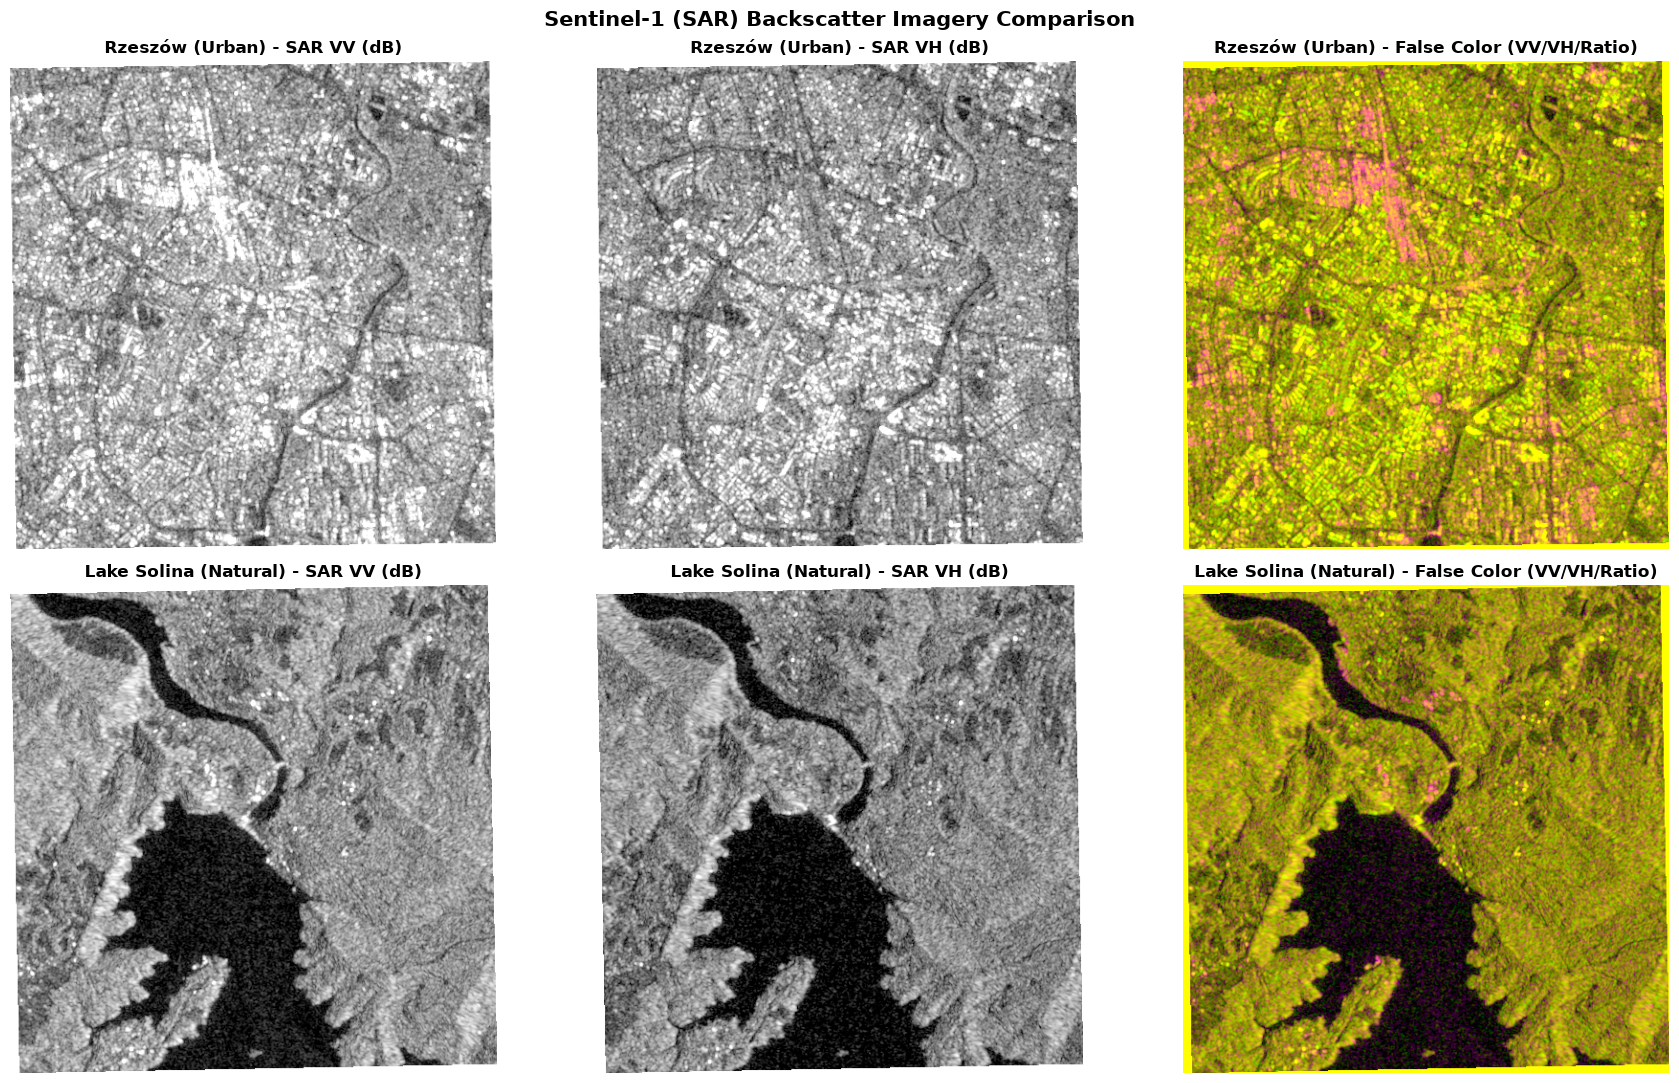

In [8]:
def prepare_sar_display(s1_dict):
    
    vv_lin = np.clip(s1_dict['VV'], 1e-5, None)
    vh_lin = np.clip(s1_dict['VH'], 1e-5, None)
    
    vv_db = 10.0 * np.log10(vv_lin)
    vh_db = 10.0 * np.log10(vh_lin)
    
    vv_norm = np.clip((vv_db - (-25.0)) / (0.0 - (-25.0)), 0, 1)
    vh_norm = np.clip((vh_db - (-30.0)) / (-5.0 - (-30.0)), 0, 1)
    
    ratio_norm = np.clip(vv_norm - vh_norm, 0, 1)
    sar_rgb = np.dstack((vv_norm, vh_norm, ratio_norm))
    
    return vv_norm, vh_norm, sar_rgb

rzeszow_vv, rzeszow_vh, rzeszow_rgb = prepare_sar_display(s1_urban)
solina_vv, solina_vh, solina_rgb = prepare_sar_display(s1_natural)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

axes[0, 0].imshow(rzeszow_vv, cmap='gray')
axes[0, 0].set_title('Rzeszów (Urban) - SAR VV (dB)', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')
axes[0, 1].imshow(rzeszow_vh, cmap='gray')
axes[0, 1].set_title('Rzeszów (Urban) - SAR VH (dB)', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')
axes[0, 2].imshow(rzeszow_rgb)
axes[0, 2].set_title('Rzeszów (Urban) - False Color (VV/VH/Ratio)', fontsize=12, fontweight='bold')
axes[0, 2].axis('off')

axes[1, 0].imshow(solina_vv, cmap='gray')
axes[1, 0].set_title('Lake Solina (Natural) - SAR VV (dB)', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')
axes[1, 1].imshow(solina_vh, cmap='gray')
axes[1, 1].set_title('Lake Solina (Natural) - SAR VH (dB)', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')
axes[1, 2].imshow(solina_rgb)
axes[1, 2].set_title('Lake Solina (Natural) - False Color (VV/VH/Ratio)', fontsize=12, fontweight='bold')
axes[1, 2].axis('off')

plt.suptitle('Sentinel-1 (SAR) Backscatter Imagery Comparison', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

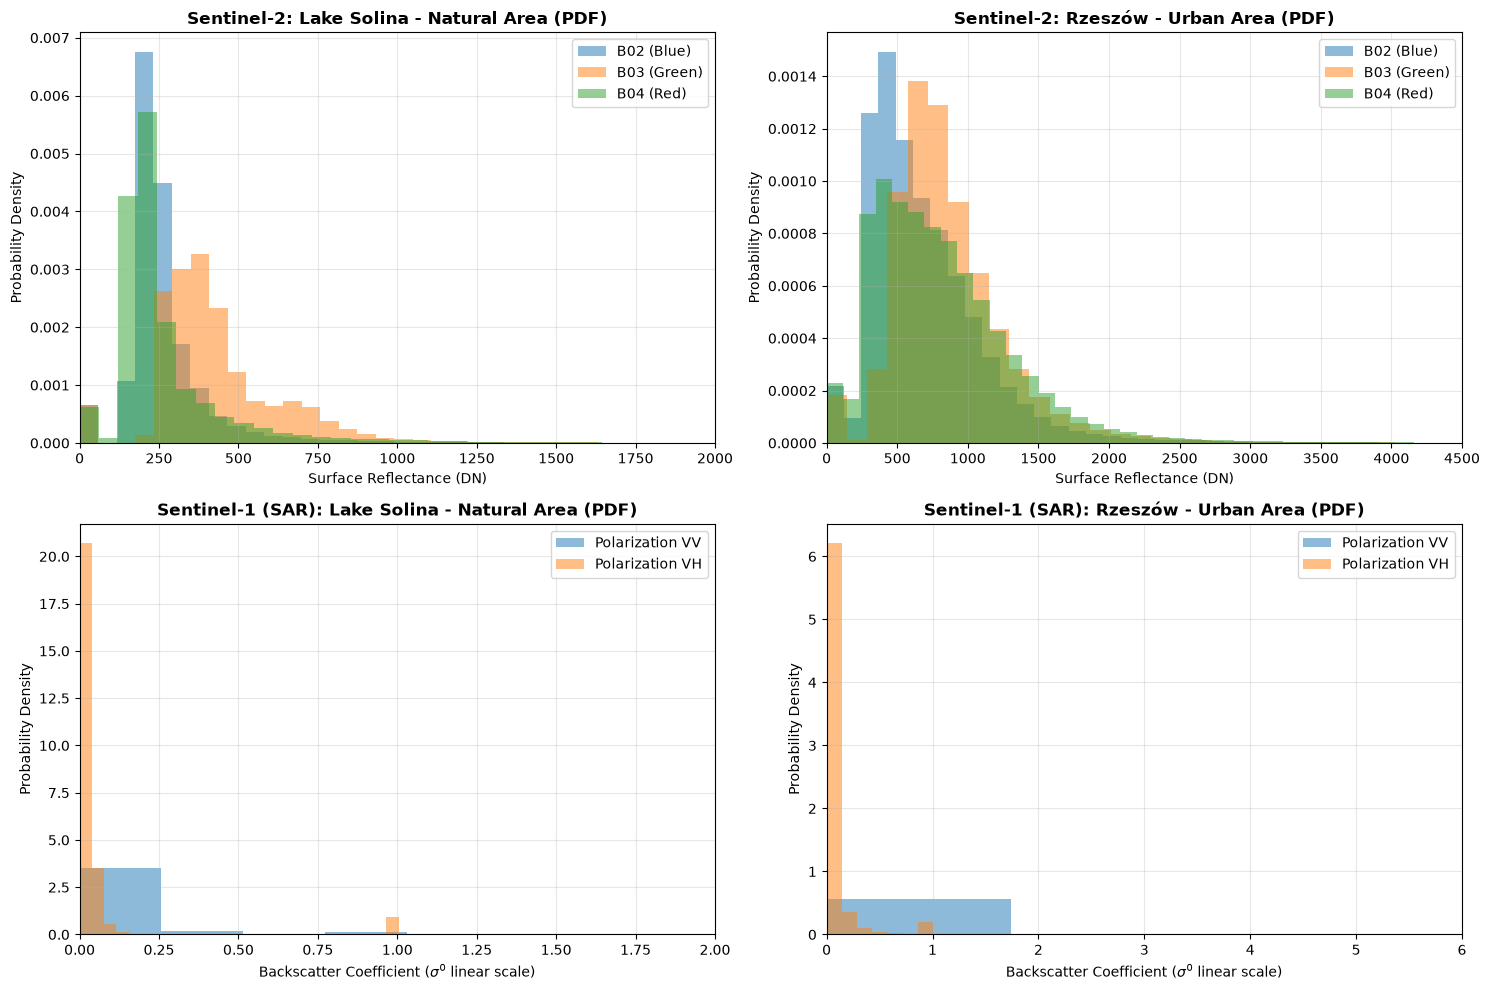

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Sentinel-2: Lake Solina
for band_name, data in s2_natural.items():
    flat_data = data.flatten()
    axes[0, 0].hist(flat_data, bins=120, density=True, alpha=0.5, label=band_name)

axes[0, 0].set_xlim([0, 2000])
axes[0, 0].set_title('Sentinel-2: Lake Solina - Natural Area (PDF)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Surface Reflectance (DN)')
axes[0, 0].set_ylabel('Probability Density')
axes[0, 0].legend(loc='upper right')
axes[0, 0].grid(True, alpha=0.3)

# Sentinel-2: Urban Area (Rzeszów)
for band_name, data in s2_urban.items():
    flat_data = data.flatten()
    axes[0, 1].hist(flat_data, bins=120, density=True, alpha=0.5, label=band_name)

axes[0, 1].set_xlim([0, 4500])
axes[0, 1].set_title('Sentinel-2: Rzeszów - Urban Area (PDF)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Surface Reflectance (DN)')
axes[0, 1].set_ylabel('Probability Density')
axes[0, 1].legend(loc='upper right')
axes[0, 1].grid(True, alpha=0.3)

# Sentinel-1 (SAR): Lake Solina
for pol_name, data in s1_natural.items():
    flat_data = data.flatten()
    axes[1, 0].hist(flat_data, bins=120, density=True, alpha=0.5, label=f'Polarization {pol_name}')

axes[1, 0].set_xlim([0, 2.0])
axes[1, 0].set_title('Sentinel-1 (SAR): Lake Solina - Natural Area (PDF)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel(r'Backscatter Coefficient ($\sigma^0$ linear scale)')
axes[1, 0].set_ylabel('Probability Density')
axes[1, 0].legend(loc='upper right')
axes[1, 0].grid(True, alpha=0.3)

# Sentinel-1 (SAR): Urban Area (Rzeszów)
for pol_name, data in s1_urban.items():
    flat_data = data.flatten()
    axes[1, 1].hist(flat_data, bins=120, density=True, alpha=0.5, label=f'Polarization {pol_name}')

axes[1, 1].set_xlim([0, 6.0])
axes[1, 1].set_title('Sentinel-1 (SAR): Rzeszów - Urban Area (PDF)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel(r'Backscatter Coefficient ($\sigma^0$ linear scale)')
axes[1, 1].set_ylabel('Probability Density')
axes[1, 1].legend(loc='upper right')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

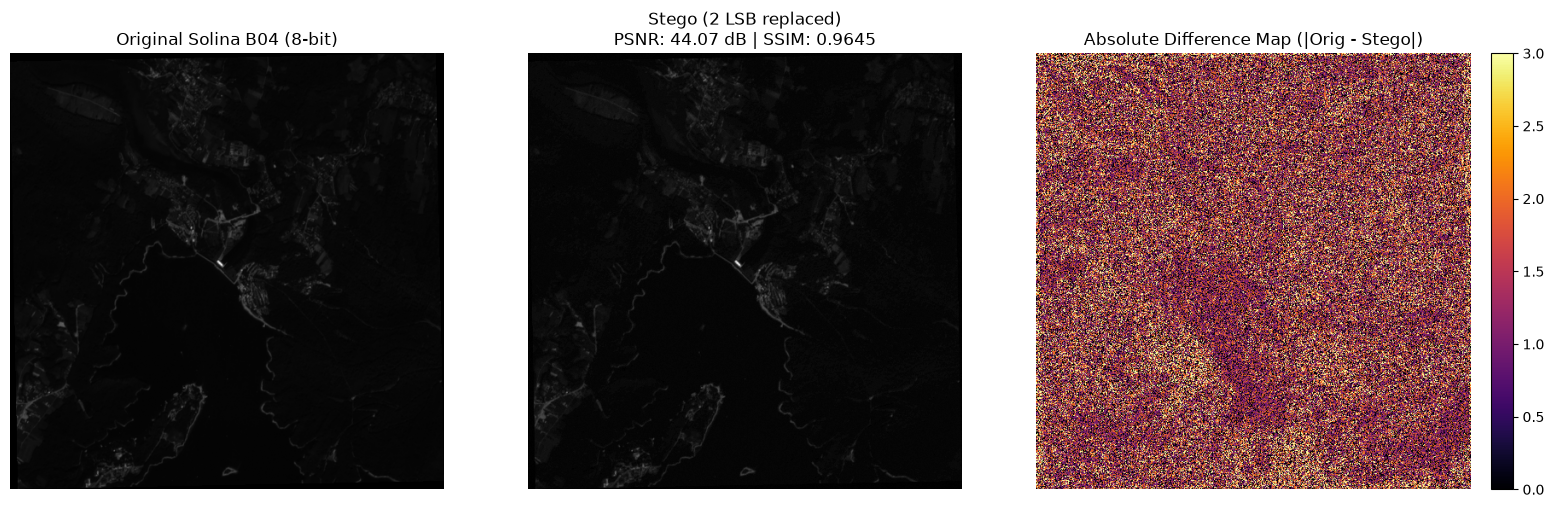

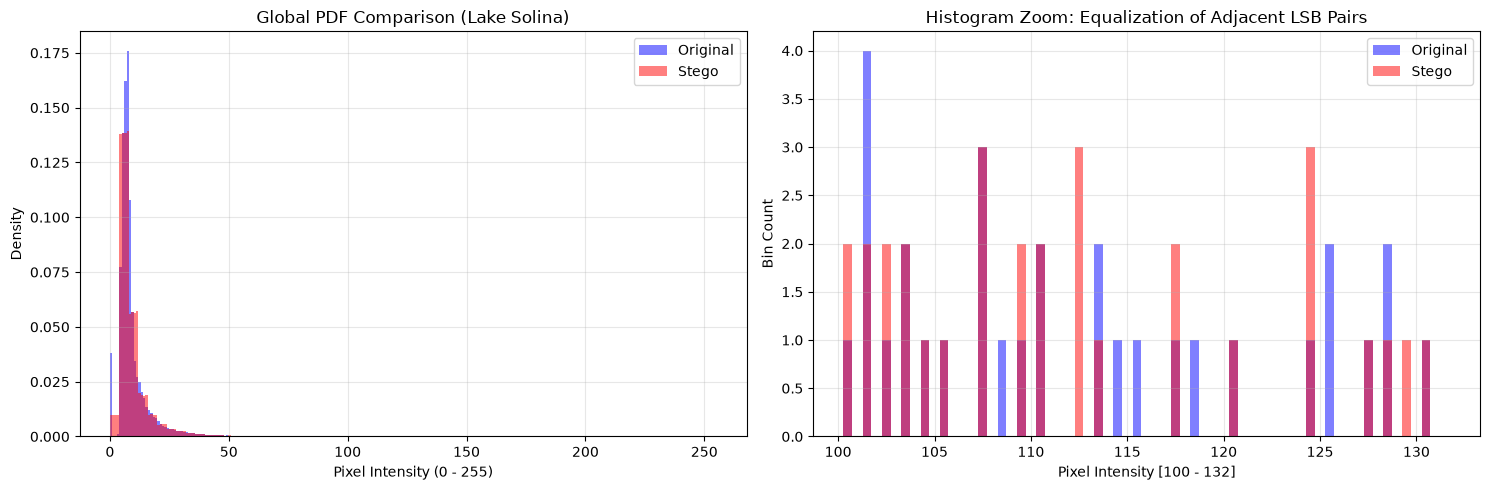

In [ ]:
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

#Lake Solina (B04)
img_solina = s2_natural['B04 (Red)']

img_solina = np.nan_to_num(img_solina)
orig_8bit = ((img_solina - np.min(img_solina)) / np.ptp(img_solina) * 255.0).astype(np.uint8)

# replace 2 LSBs with pseudo-random bits
np.random.seed(42)
rand_2bits = np.random.randint(0, 4, size=orig_8bit.shape, dtype=np.uint8)
stego_8bit = (orig_8bit & 0xFC) | rand_2bits

psnr_val = psnr(orig_8bit, stego_8bit)
ssim_val = ssim(orig_8bit, stego_8bit)

diff_map = np.abs(orig_8bit.astype(np.int16) - stego_8bit.astype(np.int16))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(orig_8bit, cmap='gray')
axes[0].set_title('Original Solina B04 (8-bit)')
axes[0].axis('off')

axes[1].imshow(stego_8bit, cmap='gray')
axes[1].set_title(f'Stego (2 LSB replaced)\nPSNR: {psnr_val:.2f} dB | SSIM: {ssim_val:.4f}')
axes[1].axis('off')

im_d = axes[2].imshow(diff_map, cmap='inferno')
axes[2].set_title('Absolute Difference Map (|Orig - Stego|)')
axes[2].axis('off')
fig.colorbar(im_d, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# histogram PDF 
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(orig_8bit.flatten(), bins=256, range=(0, 255), density=True, alpha=0.5, color='blue', label='Original')
axes[0].hist(stego_8bit.flatten(), bins=256, range=(0, 255), density=True, alpha=0.5, color='red', label='Stego')
axes[0].set_title('Global PDF Comparison (Lake Solina)')
axes[0].set_xlabel('Pixel Intensity (0 - 255)')
axes[0].set_ylabel('Density')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(orig_8bit.flatten(), bins=32, range=(100, 132), alpha=0.5, color='blue', label='Original', rwidth=0.45)
axes[1].hist(stego_8bit.flatten(), bins=32, range=(100, 132), alpha=0.5, color='red', label='Stego', rwidth=0.45)
axes[1].set_title('Histogram Zoom: Equalization of Adjacent LSB Pairs')
axes[1].set_xlabel('Pixel Intensity [100 - 132]')
axes[1].set_ylabel('Bin Count')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1. Probability Distribution Function (PDF) Analysis

#### Observations & Comparison:

* **Sentinel-2 (Optical): Natural vs. Urban**
  * **Natural Area (Lake Solina):** Most pixel values are clustered at the lower end of the brightness scale. Water absorbs almost all light and looks very dark, while trees and plants absorb red light for photosynthesis. Because of this, the curves look smooth, narrow, and peak at lower numbers.
  * **Urban Area (Rzeszów):** The values are much more spread out, and the histogram has a long tail reaching higher brightness levels. Cities have all kinds of artificial surfaces—like concrete, asphalt, metal roofs, and windows—which reflect a lot of light. This creates multiple bumps (peaks) on the chart.

* **Sentinel-1 (SAR / Radar): Natural vs. Urban**
  * **Natural Area:** Calm water acts like a mirror and bounces the radar pulse away, so it comes back almost black (values close to 0). Trees scatter the signal softly in all directions. The cross-polarization (VH) signal is much weaker than the vertical one (VV).
  * **Urban Area:** Buildings and flat streets create 90-degree corners that act like reflectors, bouncing the radar signal straight back to the satellite (called double-bounce). This causes intense bright spikes on the image and pushes the VV curve much further to the right compared to the natural landscape.

### 2. Steganography & Manipulation Detection

#### 1. Visual Quality Impact:
* **Does it affect image quality?**
  * **No, not to the human eye.**
  * The two least significant bits (LSB) only control tiny brightness steps (at most a change of 1 to 3 out of 255 levels).
  * To anyone looking at the screen, the image looks 100% normal and identical to the original. High PSNR and SSIM scores back this up mathematically.

#### 2. Histogram Changes & Detecting Tampering:
* **Can you see any difference in the PDF?**
  * **Looking at the big picture:** No, the overall shape, peak, and width of the histogram look completely untouched.
  * **Zooming in really close:** Yes, there is a clear tell. In a real satellite image, neighboring color values naturally go up and down unevenly. When we overwrite the last two bits with random numbers, we artificially even out groups of four neighboring bins. This creates an unnatural "flattening" effect known as Pairs of Values (PoV).
* **Can this be used to detect image manipulation?**
  * **Yes.** This flattening effect is exactly what steganalysis tools look for (like the Chi-Square test). Even though a person cannot see the change, a quick script can spot that the random noise in the lowest bits isn't natural sensor noise, proving the image was altered.
  * Additionally, satellite data is used for science—messing with these bits ruins calibration and messes up vegetation indices like NDVI.

### 3. Compressive Sensing in Earth Observation (EO)

#### Why is this useful for satellites?

Compressive Sensing is basically a way to capture a signal using far fewer measurements than normal (well below the traditional Nyquist rule), and then rebuild the full picture using smart optimization algorithms. 

Here is where it helps in real-world Earth Observation:

* **Hyperspectral Cameras:** These satellites capture hundreds of narrow color bands, creating massive files that are hard to store onboard. With Compressive Sensing, the camera hardware can compress the image while taking it, meaning lighter and cheaper hardware on the satellite.
* **Saving Bandwidth on CubeSats:** Small satellites have tiny batteries and only pass over ground antennas for a few minutes a day. Compressive Sensing lets them take fewer raw measurements, send the smaller data package down to Earth, and let powerful ground computers do the heavy lifting to reconstruct the full scene.
* **Better Radar (SAR) Images:** Standard radar has to balance between taking wide images or sharp, high-resolution images. Compressive Sensing lets radar satellites pulse less often without losing quality, making it possible to take wide, detailed images at the same time.


### 3.1. Compressive Sensing – Practical Demonstration

The following experiment demonstrates the basic principle of Compressive Sensing using a synthetic signal composed of two sinusoidal components.
The signal consists of 500 samples. Its representation in the Discrete Cosine Transform (DCT) domain is sparse, meaning that most of its information is concentrated in a relatively small number of coefficients.
The objective is to reconstruct the original signal using only a limited number of randomly selected measurements.


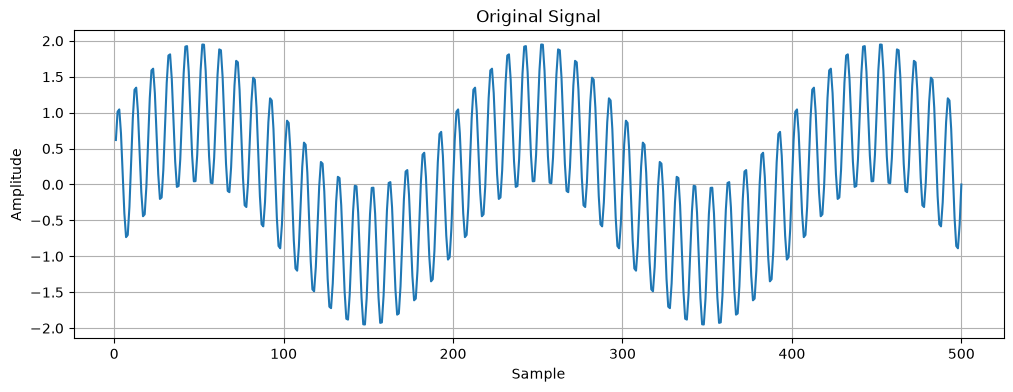

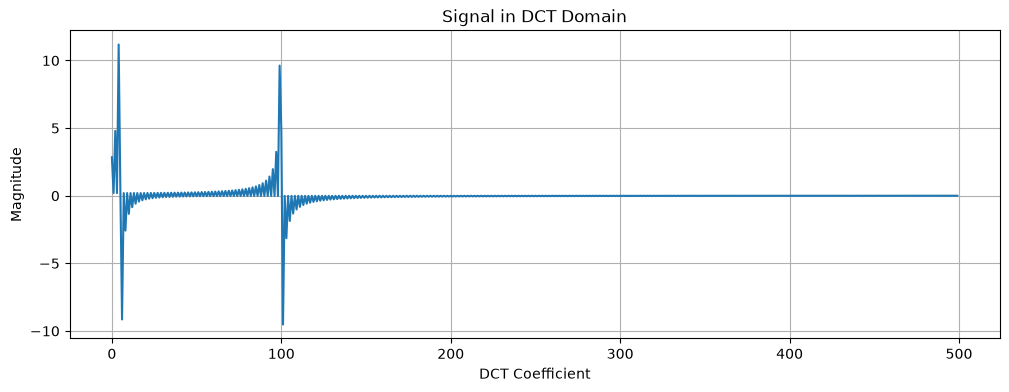

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize, fftpack

#generate a signal consisting of two sinusoids
N = 500
t = np.linspace(1, 500, N)

xx = np.sin(2 * np.pi * t / 10) + np.sin(2 * np.pi * t / 200)

# plot original signal
plt.figure(figsize=(12, 4))
plt.plot(t, xx)
plt.title("Original Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

#transform signal into DCT domain
plt.figure(figsize=(12, 4))
plt.plot(fftpack.dct(xx, norm='ortho'))
plt.title("Signal in DCT Domain")
plt.xlabel("DCT Coefficient")
plt.ylabel("Magnitude")
plt.grid()
plt.show()



### 3.2. Sparse Sampling

Instead of using all 500 measurements, we randomly select only 50 samples (10% of the original signal).
The remaining samples are treated as unknown. This simulates a reduced data acquisition process.


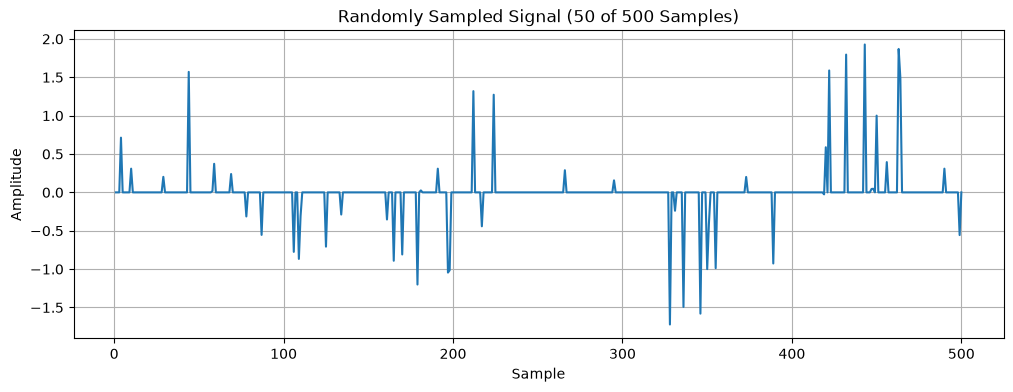

In [ ]:

#randomly select 50 samples
n = 50

sp = np.array([1] * n + [0] * (N - n))
np.random.shuffle(sp)

xp = xx * sp

plt.figure(figsize=(12, 4))
plt.plot(t, xp)
plt.title("Randomly Sampled Signal (50 of 500 Samples)")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid()
plt.show()



### 3.3. Signal Reconstruction Using Optimization

The reconstruction process uses the fact that the original signal is sparse in the DCT domain.
An optimization algorithm attempts to recover the original signal from the available measurements.
First, we minimize the reconstruction error. Then, we introduce sparsity constraints using L0 and L1 norms to improve the reconstruction.


c:\Users\Dell\Desktop\MS2\Machine learning\ML4Space\.venv\Lib\site-packages\scipy\optimize\_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


         Current function value: 0.000001
         Iterations: 3
         Function evaluations: 33579
         Gradient evaluations: 67


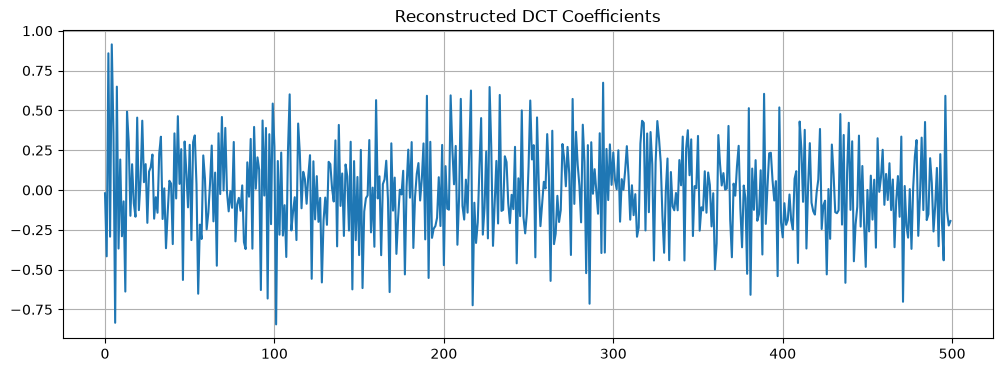

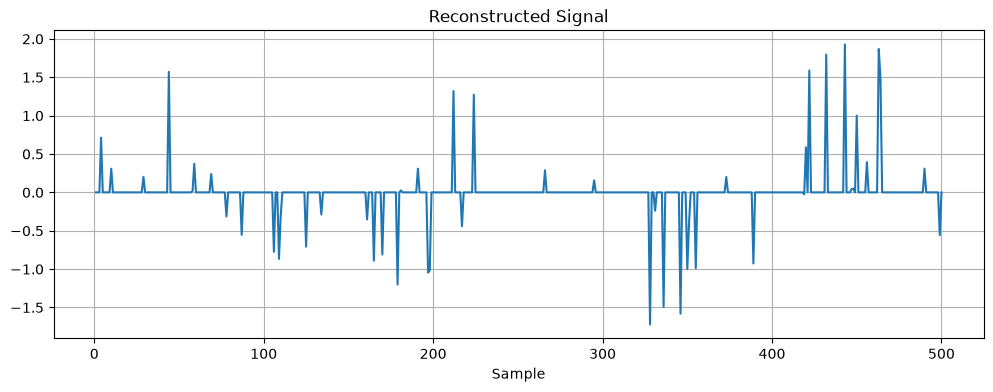

In [11]:

XX = np.random.rand(N)

def cost_cs(XX):
    xd = fftpack.idct(XX, norm='ortho')
    xdn = xd * sp
    return np.linalg.norm((xdn - xp), ord=2)

seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')

plt.figure(figsize=(12, 4))
plt.plot(CS.x)
plt.title("Reconstructed DCT Coefficients")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(t, xrecon)
plt.title("Reconstructed Signal")
plt.xlabel("Sample")
plt.grid()
plt.show()


Iteration limit reached    (Exit mode 9)
            Current function value: 2.863286417375565e-05
            Iterations: 100
            Function evaluations: 51095
            Gradient evaluations: 101


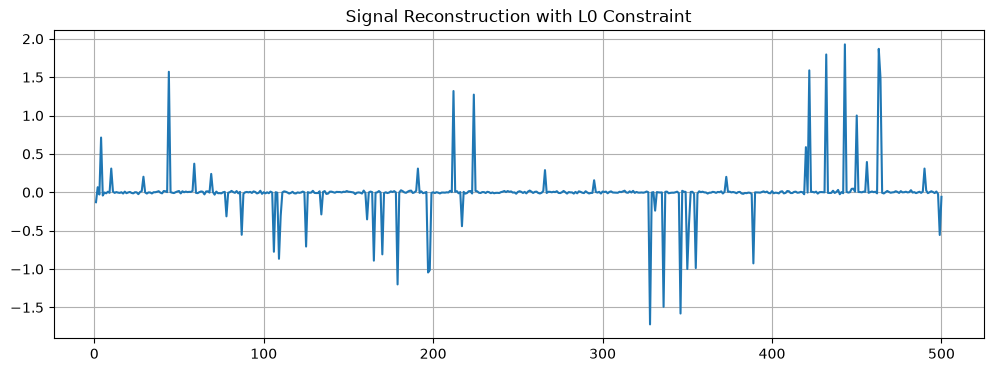

In [12]:

def cost_cs(XX):
    xd = fftpack.idct(XX, norm='ortho')
    xdn = xd * sp
    return np.linalg.norm((xdn - xp), ord=2)

cons = ({
    'type': 'ineq',
    'fun': lambda XX: n - np.linalg.norm(XX, ord=0)
})

seed = np.zeros(N)

CS = optimize.minimize(
    cost_cs,
    seed,
    constraints=cons,
    options={'disp': True}
)

xrecon = fftpack.idct(CS.x, norm='ortho')

plt.figure(figsize=(12, 4))
plt.plot(t, xrecon)
plt.title("Signal Reconstruction with L0 Constraint")
plt.grid()
plt.show()


Iteration limit reached    (Exit mode 9)
            Current function value: 60.6518700091646
            Iterations: 100
            Function evaluations: 50900
            Gradient evaluations: 101


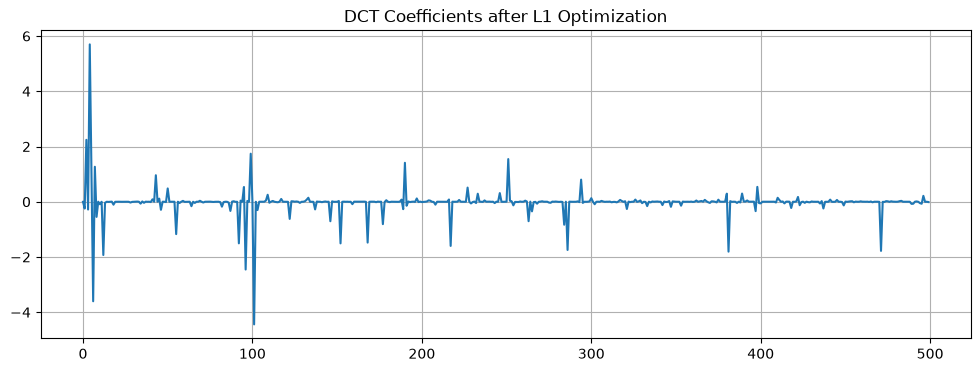

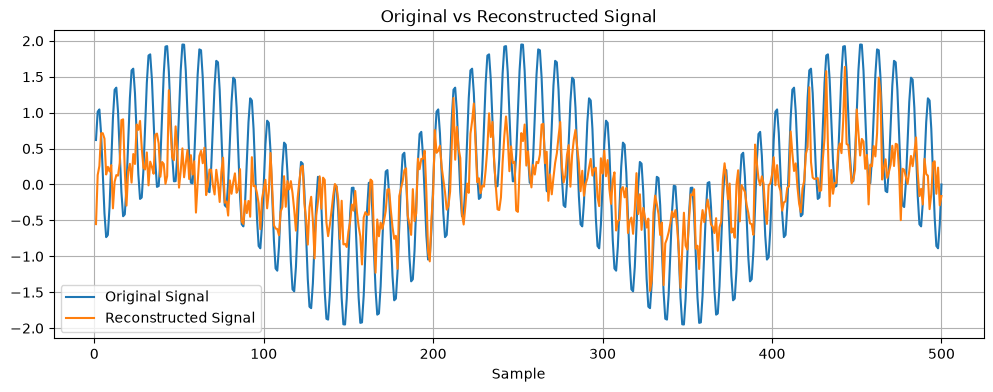

In [13]:

def cost_cs(XX):
    return np.linalg.norm(XX, ord=1)

cons = ({
    'type': 'eq',
    'fun': lambda XX: np.linalg.norm(
        xp - fftpack.idct(XX, norm='ortho') * sp,
        ord=2
    )
})

seed = np.random.rand(N)

CS = optimize.minimize(
    cost_cs,
    seed,
    constraints=cons,
    options={'disp': True}
)

xrecon = fftpack.idct(CS.x, norm='ortho')

plt.figure(figsize=(12, 4))
plt.plot(CS.x)
plt.title("DCT Coefficients after L1 Optimization")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(t, xx, label="Original Signal")
plt.plot(t, xrecon, label="Reconstructed Signal")
plt.title("Original vs Reconstructed Signal")
plt.xlabel("Sample")
plt.legend()
plt.grid()
plt.show()



### 3.4. Results and Conclusions

The experiment demonstrates the basic principle of Compressive Sensing.

* The original signal contains 500 samples, while the reconstruction uses only 50 randomly selected measurements.
* The DCT representation allows the signal to be described using a relatively small number of significant coefficients.
* The optimization process attempts to recover the original signal by exploiting its sparsity in the DCT domain.
* L1 minimization encourages a sparse representation and can improve the reconstruction compared to minimizing the measurement error alone.

The reconstruction may contain noise or deviations from the original signal due to the limited number of measurements and optimization constraints.

**Potential applications in Earth Observation:**

Compressive Sensing can be useful for:
* Hyperspectral imaging, reducing the amount of acquired spectral data.
* CubeSat missions, reducing onboard storage requirements and transmission bandwidth.
* SAR imaging, enabling efficient acquisition and reconstruction of radar data.

In general, Compressive Sensing can help reduce the amount of data collected or transmitted by satellites while preserving the possibility of reconstructing useful information.
